> **Brouillon historique d’analyse.** Ce notebook conserve les premiers graphiques et calculs sur 1 025 espèces représentées par leur variété par défaut. Il ne constitue pas encore l’analyse de toutes les formes. La collecte de référence se trouve dans `01_collecte.ipynb` ; l’analyse sera adaptée après l’EDA et la préparation. Les sorties ci-dessous sont celles de l’ancien scénario.

# Projet Data Science : Evolution des statistiques des Pokemon par generation
Auteur: Ariël, Safaa, Paul
## Problematique
Les generations recentes introduisent-elles des Pokemon aux statistiques plus elevees ou plus specialises ?

## Hypotheses
- H1 : Le total des statistiques de base (BST) augmente avec les generations.
- H2 : Les profils statistiques deviennent plus specialises.

Les Pokemon sont etudies selon leur generation d'introduction. Les formes alternatives ne sont pas comptees comme de nouvelles especes. Les legendaires et fabuleux seront egalement analyses separement.

## 1. Importation des bibliotheques

Dans cette cellule, nous importons les différentes bibliothèques nécessaires à notre projet. Pandas et NumPy permettent de manipuler et traiter les données, Matplotlib et Seaborn servent à créer des visualisations, SciPy fournit les outils nécessaires aux tests statistiques et Requests permet de communiquer avec l'API PokéAPI. Nous configurons également l'apparence des graphiques et préparons un dossier qui servira à stocker les données téléchargées.

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import json
from scipy import stats
from IPython.display import display

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

BASE_URL = 'https://pokeapi.co/api/v2/'
CACHE_DIR = 'pokeapi_cache'
os.makedirs(CACHE_DIR, exist_ok=True)

print('Bibliotheques chargees avec succes !')

Bibliotheques chargees avec succes !


## 2. Recuperation des donnees depuis PokéAPI

Cette cellule permet de récupérer automatiquement les données des Pokémon des neuf générations à partir de PokéAPI. Nous créons une fonction qui interroge l'API et sauvegarde les réponses dans un cache local afin d'éviter les téléchargements répétitifs. Pour chaque espèce, nous récupérons sa forme par défaut, ses types, ses six statistiques de base ainsi que les informations permettant d'identifier les Pokémon légendaires et fabuleux. Enfin, nous regroupons toutes les informations dans un DataFrame Pandas.

In [2]:
session = requests.Session()


def get_api(url):
    filename = os.path.join(CACHE_DIR, str(abs(hash(url))) + '.json')

    if os.path.exists(filename):
        with open(filename, 'r', encoding='utf-8') as f:
            return json.load(f)

    response = session.get(url, timeout=30)
    response.raise_for_status()
    data = response.json()

    with open(filename, 'w', encoding='utf-8') as f:
        json.dump(data, f)

    time.sleep(0.05)
    return data


pokemon_data = []

for generation in range(1, 10):
    print(f'Recuperation generation {generation}...')

    gen_data = get_api(f'{BASE_URL}generation/{generation}/')

    for species in gen_data['pokemon_species']:
        species_data = get_api(species['url'])

        default_variety = next(
            (v for v in species_data['varieties'] if v['is_default']),
            None
        )

        if default_variety is None:
            continue

        pokemon = get_api(default_variety['pokemon']['url'])

        row = {
            'id': species_data['id'],
            'name': species_data['name'],
            'generation': generation,
            'is_legendary': species_data['is_legendary'],
            'is_mythical': species_data['is_mythical'],
            'types': ', '.join(t['type']['name'] for t in pokemon['types'])
        }

        for stat in pokemon['stats']:
            row[stat['stat']['name']] = stat['base_stat']

        pokemon_data.append(row)


df = pd.DataFrame(pokemon_data)
df = df.drop_duplicates(subset='id').reset_index(drop=True)

print('\nCollecte terminee !')
print('Nombre de Pokemon :', len(df))
display(df.head())

Recuperation generation 1...
Recuperation generation 2...
Recuperation generation 3...
Recuperation generation 4...
Recuperation generation 5...
Recuperation generation 6...
Recuperation generation 7...
Recuperation generation 8...
Recuperation generation 9...

Collecte terminee !
Nombre de Pokemon : 1025


,id,name,generation,is_legendary,is_mythical,types,hp,attack,defense,special-attack,special-defense,speed
0,1,bulbasaur,1,False,False,"grass, poison",45,49,49,65,65,45
1,2,ivysaur,1,False,False,"grass, poison",60,62,63,80,80,60
2,3,venusaur,1,False,False,"grass, poison",80,82,83,100,100,80
3,4,charmander,1,False,False,fire,39,52,43,60,50,65
4,5,charmeleon,1,False,False,fire,58,64,58,80,65,80


## 3. Nettoyage et preparation des donnees

Le BST (Base Stat Total) correspond a la somme des six statistiques : PV, Attaque, Defense, Attaque Speciale, Defense Speciale et Vitesse.

Pour mesurer la specialisation, on utilise le coefficient de variation des six statistiques : ecart-type divise par moyenne. Plus il est eleve, plus le profil est contraste.

Cette mesure ne represente pas directement la performance en combat, mais permet de comparer les profils. ////Dans cette cellule, nous préparons les données pour faciliter leur analyse. Nous vérifions d'abord la présence de valeurs manquantes et supprimons les lignes incomplètes. Nous calculons ensuite trois indicateurs :
Le BST, qui correspond à la somme des six statistiques de base.
Le coefficient de variation, qui permet de mesurer la dispersion des statistiques et donc le degré de spécialisation du Pokémon.
L'écart entre la statistique maximale et minimale.
Enfin, nous créons une variable permettant de distinguer les Pokémon normaux, légendaires et fabuleux.

In [3]:
stat_cols = ['hp', 'attack', 'defense', 'special-attack', 'special-defense', 'speed']

print('Valeurs manquantes :')
print(df[stat_cols].isna().sum())

# Suppression des lignes incompletes
df = df.dropna(subset=stat_cols).copy()

# Total des statistiques de base
df['BST'] = df[stat_cols].sum(axis=1)

# Specialisation : coefficient de variation
df['specialization'] = (
    df[stat_cols].std(axis=1, ddof=0) /
    df[stat_cols].mean(axis=1)
)

# Ecart entre la statistique maximale et minimale
df['stat_gap'] = df[stat_cols].max(axis=1) - df[stat_cols].min(axis=1)

# Categorie pour analyses complementaires
df['legendary_status'] = np.where(
    df['is_legendary'], 'Legendary',
    np.where(df['is_mythical'], 'Mythical', 'Normal')
)

print('Dimensions du dataset :', df.shape)
display(df.head())
print(df.describe())

Valeurs manquantes :
hp                 0
attack             0
defense            0
special-attack     0
special-defense    0
speed              0
dtype: int64
Dimensions du dataset : (1025, 16)


,id,name,generation,is_legendary,is_mythical,types,hp,attack,defense,special-attack,special-defense,speed,BST,specialization,stat_gap,legendary_status
0,1,bulbasaur,1,False,False,"grass, poison",45,49,49,65,65,45,318,0.163038,20,Normal
1,2,ivysaur,1,False,False,"grass, poison",60,62,63,80,80,60,405,0.131885,20,Normal
2,3,venusaur,1,False,False,"grass, poison",80,82,83,100,100,80,525,0.101740,20,Normal
3,4,charmander,1,False,False,fire,39,52,43,60,50,65,309,0.174667,26,Normal
4,5,charmeleon,1,False,False,fire,58,64,58,80,65,80,405,0.136787,22,Normal


                id   generation           hp       attack      defense  \
count  1025.000000  1025.000000  1025.000000  1025.000000  1025.000000   
mean    513.000000     4.741463    70.184390    77.521951    72.507317   
std     296.036315     2.633633    26.631054    29.782541    29.286972   
min       1.000000     1.000000     1.000000     5.000000     5.000000   
25%     257.000000     3.000000    50.000000    55.000000    50.000000   
50%     513.000000     5.000000    68.000000    75.000000    70.000000   
75%     769.000000     7.000000    85.000000   100.000000    90.000000   
max    1025.000000     9.000000   255.000000   181.000000   230.000000   

       special-attack  special-defense        speed          BST  \
count     1025.000000      1025.000000  1025.000000  1025.000000   
mean        70.080976        70.205854    67.186341   427.686829   
std         29.658378        26.639329    28.717227   112.770735   
min         10.000000        20.000000     5.000000   175.000

## 4. Analyse exploratoire

Cette cellule réalise une première synthèse des données. Nous regroupons les Pokémon par génération afin de calculer leur nombre, leur BST moyen et médian, leur écart-type ainsi que leur niveau moyen et médian de spécialisation. Ces indicateurs permettent d'obtenir une première vision des différences entre les générations avant de réaliser les analyses graphiques et statistiques.

In [4]:
summary = df.groupby('generation').agg(
    pokemon_count=('id', 'count'),
    BST_mean=('BST', 'mean'),
    BST_median=('BST', 'median'),
    BST_std=('BST', 'std'),
    specialization_mean=('specialization', 'mean'),
    specialization_median=('specialization', 'median')
).round(2)

display(summary)

,pokemon_count,BST_mean,BST_median,BST_std,specialization_mean,specialization_median
generation,,,,,,
1,151,407.64,405.0,99.88,0.29,0.26
2,100,407.18,415.0,112.46,0.29,0.26
3,135,403.73,410.0,115.57,0.29,0.25
4,107,445.57,480.0,117.25,0.27,0.24
5,156,425.76,445.5,102.47,0.26,0.24
6,72,429.31,450.0,111.73,0.24,0.22
7,88,449.41,480.0,119.15,0.29,0.27
8,96,439.22,481.5,116.30,0.27,0.24
9,120,457.39,488.5,116.61,0.26,0.24


### 4.1 Nombre de Pokemon par generation

Nous réalisons ici un graphique en barres représentant le nombre de Pokémon introduits dans chaque génération. Cette visualisation permet de comparer la taille des différentes générations et de vérifier si les effectifs sont équilibrés. Cette information est importante pour interpréter correctement les résultats des analyses suivantes.


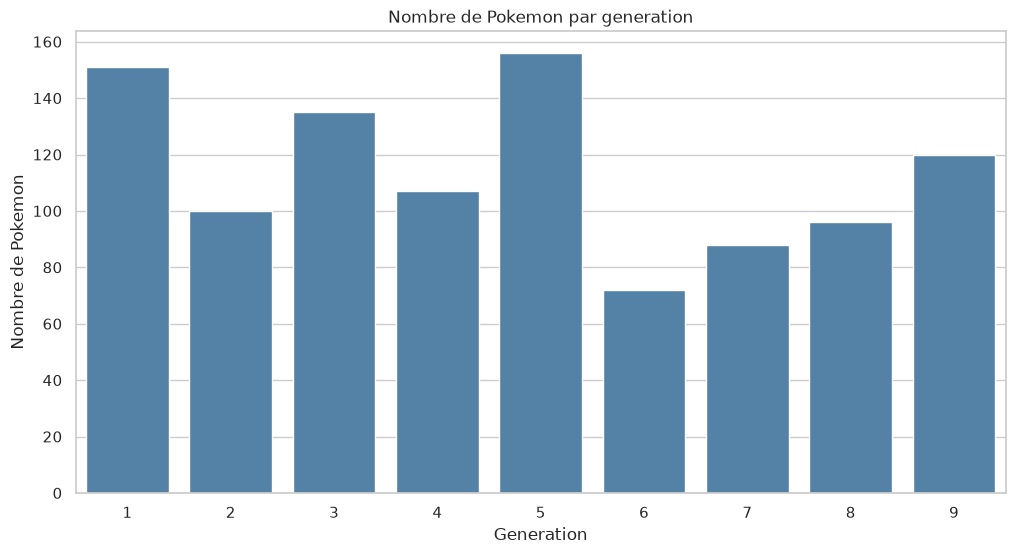

In [5]:
sns.countplot(data=df, x='generation', color='steelblue')
plt.title('Nombre de Pokemon par generation')
plt.xlabel('Generation')
plt.ylabel('Nombre de Pokemon')
plt.show()

### 4.2 Evolution du total des statistiques (BST)

Dans cette cellule, nous étudions l'évolution du total des statistiques de base des Pokémon selon leur génération. Le premier graphique utilise des boîtes à moustaches pour comparer la distribution des BST et identifier les différences de dispersion, les valeurs centrales et les éventuelles valeurs extrêmes. Le second graphique représente le BST moyen de chaque génération afin de visualiser plus facilement son évolution globale.

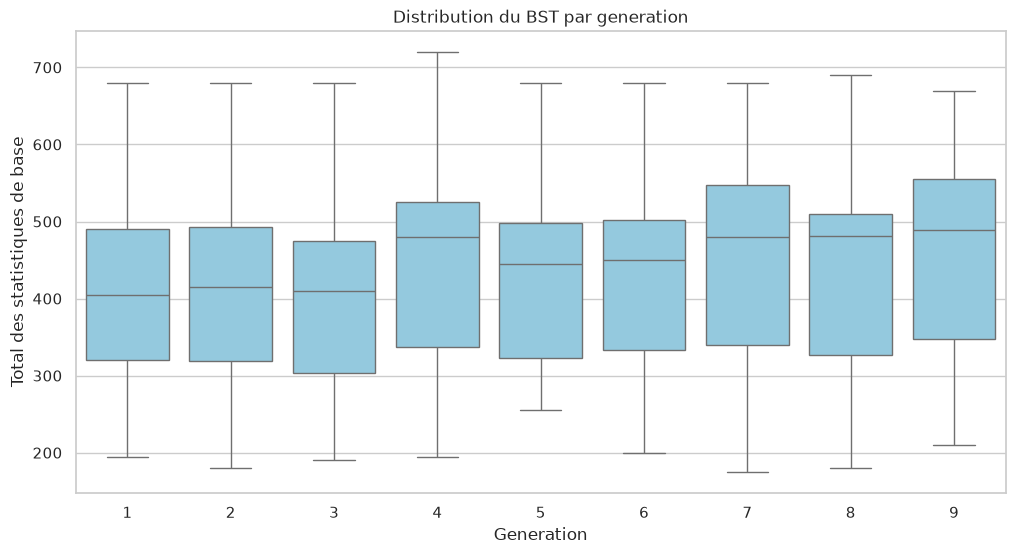

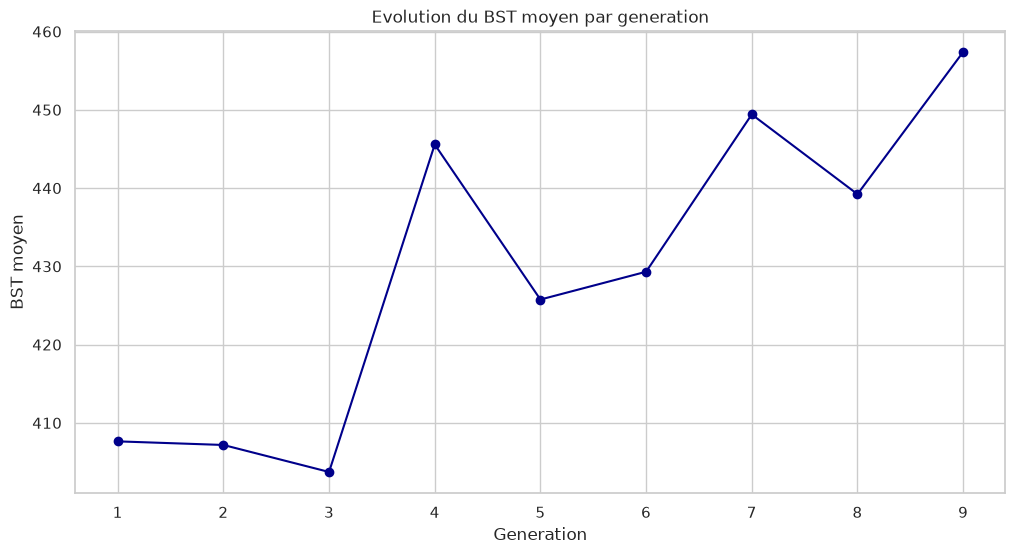

In [6]:
sns.boxplot(data=df, x='generation', y='BST', color='skyblue')
plt.title('Distribution du BST par generation')
plt.xlabel('Generation')
plt.ylabel('Total des statistiques de base')
plt.show()

summary['BST_mean'].plot(marker='o', color='darkblue')
plt.title('Evolution du BST moyen par generation')
plt.xlabel('Generation')
plt.ylabel('BST moyen')
plt.xticks(range(1, 10))
plt.show()

### 4.3 Evolution de la specialisation

Un coefficient de variation eleve indique une repartition plus inegale des statistiques d'un Pokemon.
Cette cellule permet d'étudier l'évolution de la spécialisation des Pokémon au fil des générations. Nous utilisons le coefficient de variation calculé précédemment. Le premier graphique compare la distribution de cet indicateur pour chaque génération à l'aide de boîtes à moustaches. Le second représente la spécialisation moyenne par génération. Un coefficient de variation élevé indique que les statistiques d'un Pokémon sont davantage contrastées.

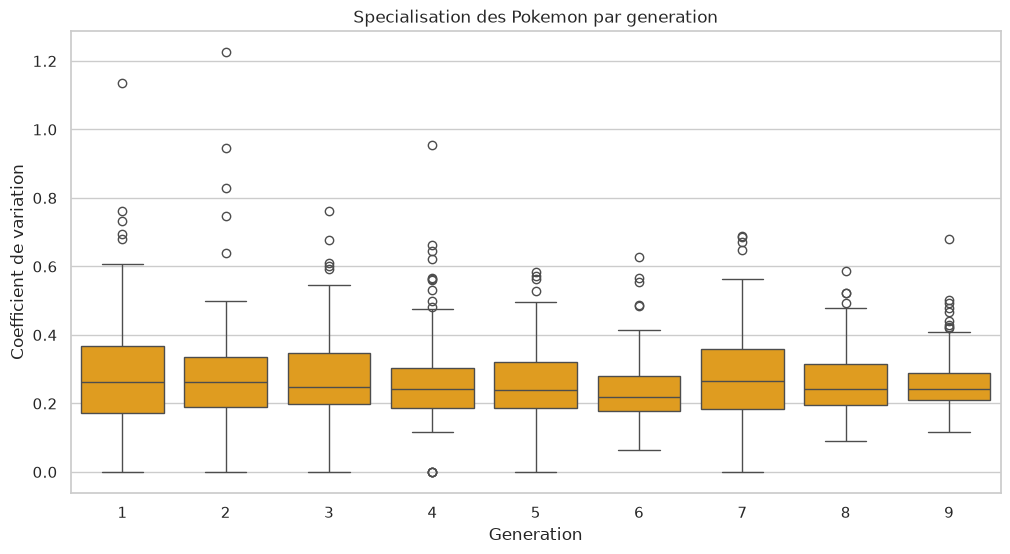

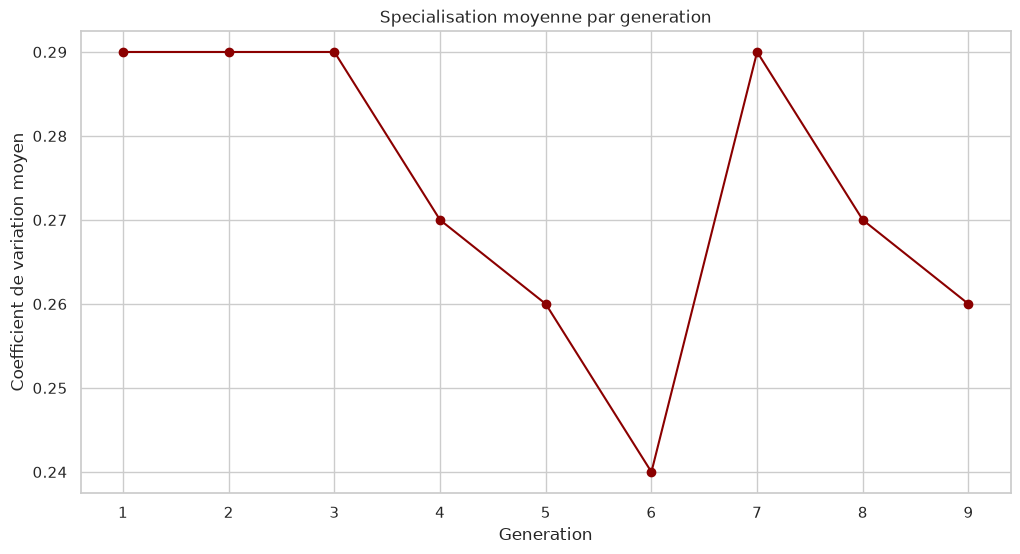

In [7]:
sns.boxplot(data=df, x='generation', y='specialization', color='orange')
plt.title('Specialisation des Pokemon par generation')
plt.xlabel('Generation')
plt.ylabel('Coefficient de variation')
plt.show()

summary['specialization_mean'].plot(marker='o', color='darkred')
plt.title('Specialisation moyenne par generation')
plt.xlabel('Generation')
plt.ylabel('Coefficient de variation moyen')
plt.xticks(range(1, 10))
plt.show()

### 4.4 Evolution des six statistiques individuelles

On compare les moyennes de PV, Attaque, Defense, Attaque Speciale, Defense Speciale et Vitesse.
Nous cherchons ici à déterminer quelles statistiques évoluent le plus au fil des générations. Pour cela, nous calculons la moyenne des six statistiques de base pour chaque génération : les PV, l'Attaque, la Défense, l'Attaque Spéciale, la Défense Spéciale et la Vitesse. Le graphique obtenu permet de comparer leurs évolutions respectives et d'identifier les statistiques qui contribuent le plus aux éventuelles variations du BST.

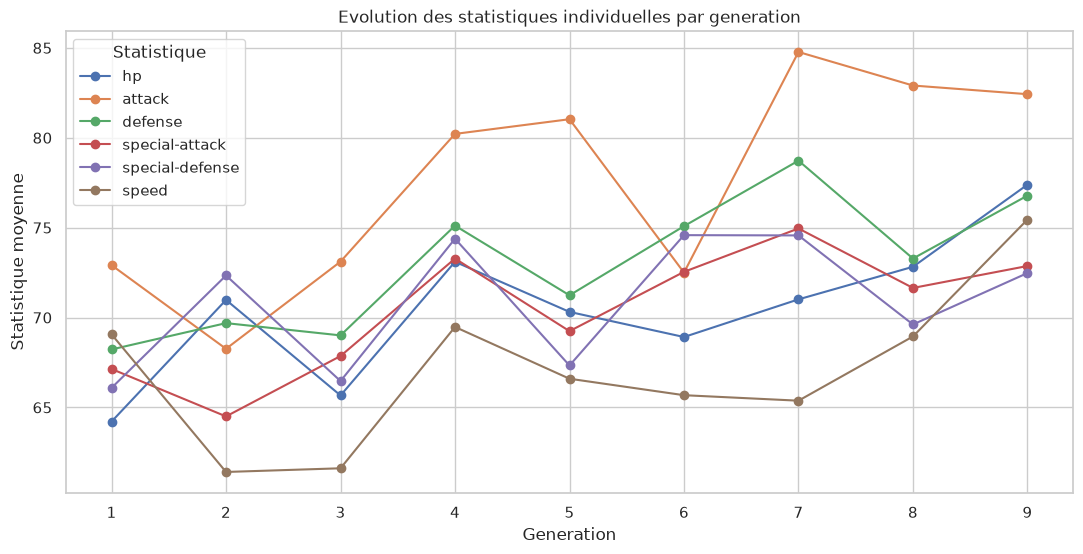

In [8]:
stat_evolution = df.groupby('generation')[stat_cols].mean()

stat_evolution.plot(marker='o', figsize=(13, 6))
plt.title('Evolution des statistiques individuelles par generation')
plt.xlabel('Generation')
plt.ylabel('Statistique moyenne')
plt.xticks(range(1, 10))
plt.legend(title='Statistique')
plt.show()

## 5. Analyse des legendaires et fabuleux

Les Pokemon legendaires et fabuleux possedent souvent des statistiques elevees. On les isole afin de verifier s'ils influencent les tendances observees.
Dans cette cellule, nous analysons séparément les Pokémon normaux, légendaires et fabuleux afin d'étudier leur influence sur les résultats globaux. Nous calculons d'abord le BST moyen de chaque catégorie pour chaque génération, puis nous comparons leurs distributions à l'aide d'un graphique. Enfin, nous créons un nouveau DataFrame contenant uniquement les Pokémon normaux. Cela permet de vérifier si les tendances observées restent présentes lorsque les Pokémon légendaires et fabuleux sont exclus de l'analyse.

legendary_status,Legendary,Mythical,Normal
generation,,,
1,605.00,600.0,400.92
2,620.00,600.0,393.81
3,620.00,600.0,386.74
4,625.56,600.0,419.85
5,613.33,595.0,409.22
6,653.33,600.0,411.36
7,540.36,540.0,429.22
8,576.82,600.0,419.29
9,571.36,600.0,444.46


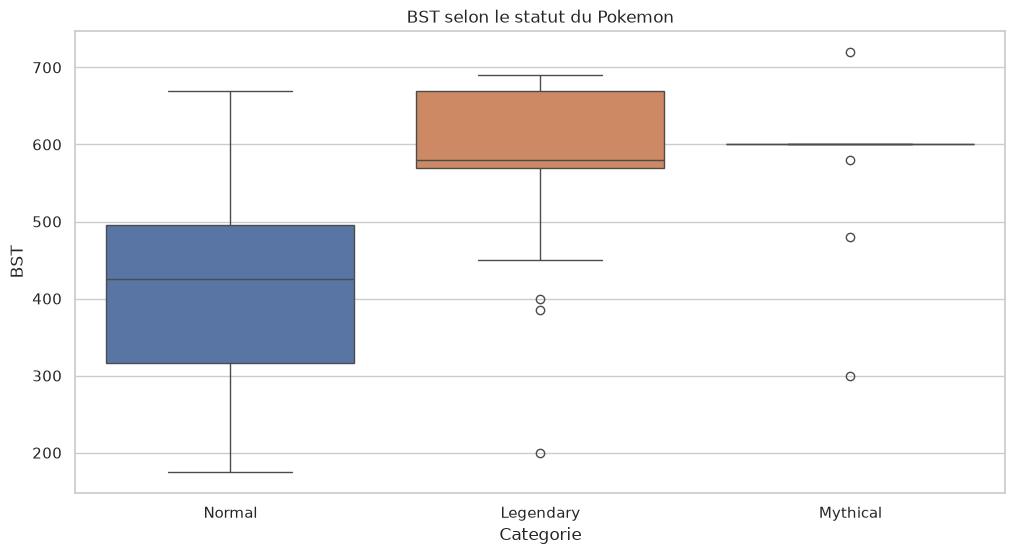

,BST_mean,specialization_mean,count
generation,,,
1,400.92,0.29,146
2,393.81,0.30,94
3,386.74,0.28,125
4,419.85,0.29,93
5,409.22,0.27,143
6,411.36,0.24,66
7,429.22,0.30,72
8,419.29,0.26,84
9,444.46,0.27,108


In [9]:
legendary_summary = df.groupby(['generation', 'legendary_status'])['BST'].mean().unstack()
display(legendary_summary.round(2))

sns.boxplot(data=df, x='legendary_status', y='BST', hue='legendary_status', legend=False)
plt.title('BST selon le statut du Pokemon')
plt.xlabel('Categorie')
plt.ylabel('BST')
plt.show()

# Analyse sans legendaires ni fabuleux
df_normal = df[df['legendary_status'] == 'Normal'].copy()
normal_summary = df_normal.groupby('generation').agg(
    BST_mean=('BST', 'mean'),
    specialization_mean=('specialization', 'mean'),
    count=('id', 'count')
).round(2)

display(normal_summary)

## 6. Tests statistiques

Nous utilisons deux approches complementaires :

- Kruskal-Wallis : determine si au moins une generation presente une distribution differente des autres.
- Spearman : mesure l'association monotone entre le numero de generation et les statistiques.

Le seuil de significativite est fixe a 5 %.
Cette cellule permet de vérifier statistiquement si le BST évolue selon les générations. Nous utilisons deux tests complémentaires :
Le test de Kruskal-Wallis permet de déterminer si les distributions du BST diffèrent significativement entre les générations.
Le coefficient de corrélation de Spearman permet de mesurer l'existence d'une relation monotone entre le numéro de génération et le BST.
Nous examinons ensuite les p-values en utilisant un seuil de significativité de 5 % afin de déterminer si l'association observée est statistiquement significative et si elle est positive ou négative.


In [10]:
groups_bst = [
    group['BST'].values
    for _, group in df.groupby('generation')
]

kw_bst = stats.kruskal(*groups_bst)

rho_bst, p_bst = stats.spearmanr(
    df['generation'], df['BST']
)

print('TEST BST')
print('Kruskal-Wallis :', kw_bst)
print('Spearman rho :', round(rho_bst, 4))
print('p-value Spearman :', p_bst)

print('\nInterpretation :')
if p_bst < 0.05:
    print('Association significative entre generation et BST.')
else:
    print('Pas d association monotone significative entre generation et BST.')

if rho_bst > 0:
    print('La tendance observee est positive.')
elif rho_bst < 0:
    print('La tendance observee est negative.')
else:
    print('Aucune tendance monotone observee.')

TEST BST
Kruskal-Wallis : KruskalResult(statistic=np.float64(35.45972141187975), pvalue=np.float64(2.2044534825790793e-05))
Spearman rho : 0.1574
p-value Spearman : 4.084899908588485e-07

Interpretation :
Association significative entre generation et BST.
La tendance observee est positive.


Nous appliquons ici la même démarche statistique à l'indicateur de spécialisation. Le test de Kruskal-Wallis permet de comparer les distributions entre générations, tandis que la corrélation de Spearman mesure l'évolution monotone de la spécialisation. Enfin, nous réalisons une analyse complémentaire du BST en excluant les Pokémon légendaires et fabuleux afin de vérifier si la tendance générale est également présente chez les Pokémon normaux.


In [11]:
groups_spec = [
    group['specialization'].values
    for _, group in df.groupby('generation')
]

kw_spec = stats.kruskal(*groups_spec)

rho_spec, p_spec = stats.spearmanr(
    df['generation'], df['specialization']
)

print('TEST SPECIALISATION')
print('Kruskal-Wallis :', kw_spec)
print('Spearman rho :', round(rho_spec, 4))
print('p-value Spearman :', p_spec)

if p_spec < 0.05:
    print('Association significative entre generation et specialisation.')
else:
    print('Pas d association monotone significative entre generation et specialisation.')

print('\nAnalyse sans legendaires et fabuleux :')
rho_normal, p_normal = stats.spearmanr(
    df_normal['generation'], df_normal['BST']
)
print('Spearman BST :', round(rho_normal, 4), 'p-value :', p_normal)

TEST SPECIALISATION
Kruskal-Wallis : KruskalResult(statistic=np.float64(8.763407354483657), pvalue=np.float64(0.3626461954361946))
Spearman rho : -0.0315
p-value Spearman : 0.31371613505650614
Pas d association monotone significative entre generation et specialisation.

Analyse sans legendaires et fabuleux :
Spearman BST : 0.1457 p-value : 8.060384072184476e-06


## 7. Identification des profils les plus specialises

On recherche les Pokemon dont le profil presente le plus grand ecart relatif entre les statistiques.
Dans cette cellule, nous recherchons les quinze Pokémon présentant les coefficients de variation les plus élevés. Nous utilisons la fonction nlargest() pour sélectionner les observations ayant les valeurs les plus importantes. Le tableau obtenu présente leur nom, leur génération, leur BST, leur coefficient de spécialisation et leurs six statistiques individuelles. Cela permet d'identifier les Pokémon possédant les profils statistiques les plus contrastés.

In [12]:
display(
    df.nlargest(15, 'specialization')[
        ['name', 'generation', 'BST', 'specialization'] + stat_cols
    ].reset_index(drop=True)
)

,name,generation,BST,specialization,hp,attack,defense,special-attack,special-defense,speed
0,shuckle,2,505,1.226325,20,10,230,10,230,5
1,chansey,1,450,1.135945,250,5,5,35,105,50
2,happiny,4,220,0.953463,100,5,5,15,65,30
3,blissey,2,540,0.946077,255,10,10,75,135,55
4,wobbuffet,2,405,0.828339,190,33,58,33,58,33
5,magikarp,1,200,0.763217,20,10,55,15,20,80
6,feebas,3,200,0.763217,20,15,20,10,55,80
7,igglybuff,2,210,0.746876,90,30,15,40,20,15
8,jigglypuff,1,270,0.734231,115,45,20,45,25,20
9,onix,1,385,0.696109,35,45,160,30,45,70


## 8. Conclusion automatique

Les resultats suivants sont calcules directement a partir du dataset recupere. Ils devront etre interpretes avec les graphiques et les limites methodologiques.
Cette dernière cellule d'analyse synthétise automatiquement les principaux résultats du projet. Nous comparons le BST moyen et la spécialisation moyenne entre la première et la neuvième génération afin de calculer leur évolution relative en pourcentage. Nous affichons également les coefficients de corrélation de Spearman et leurs p-values. Enfin, des conditions permettent de générer une interprétation automatique des tendances observées. Ces résultats constituent une première réponse à nos hypothèses, qui devra être complétée par l'interprétation des graphiques et la prise en compte des limites méthodologiques.

In [13]:
first_gen = summary.loc[1]
last_gen = summary.loc[9]

variation_bst = (last_gen['BST_mean'] / first_gen['BST_mean'] - 1) * 100
variation_spec = (last_gen['specialization_mean'] / first_gen['specialization_mean'] - 1) * 100

print('========== CONCLUSION ==========')
print(f'BST moyen generation 1 : {first_gen["BST_mean"]:.2f}')
print(f'BST moyen generation 9 : {last_gen["BST_mean"]:.2f}')
print(f'Evolution relative : {variation_bst:.2f} %')

print('\nSpecialisation moyenne generation 1 :', round(first_gen['specialization_mean'], 4))
print('Specialisation moyenne generation 9 :', round(last_gen['specialization_mean'], 4))
print(f'Evolution relative : {variation_spec:.2f} %')

print('\nTest de tendance BST :')
print('rho =', round(rho_bst, 3), '| p =', round(p_bst, 5))

print('\nTest de tendance specialisation :')
print('rho =', round(rho_spec, 3), '| p =', round(p_spec, 5))

print('\nA INTERPRETER :')
if rho_bst > 0 and p_bst < 0.05:
    print('Les generations sont associees a une hausse significative du BST.')
elif p_bst < 0.05:
    print('Les generations sont associees a une baisse significative du BST.')
else:
    print('Aucune tendance monotone significative du BST n est detectee.')

if rho_spec > 0 and p_spec < 0.05:
    print('La specialisation augmente significativement.')
elif p_spec < 0.05:
    print('La specialisation diminue significativement.')
else:
    print('Aucune tendance monotone significative de specialisation n est detectee.')

print('\nAttention : correlation ne signifie pas causalite.')

========== CONCLUSION ==========
BST moyen generation 1 : 407.64
BST moyen generation 9 : 457.39
Evolution relative : 12.20 %

Specialisation moyenne generation 1 : 0.29
Specialisation moyenne generation 9 : 0.26
Evolution relative : -10.34 %

Test de tendance BST :
rho = 0.157 | p = 0.0

Test de tendance specialisation :
rho = -0.031 | p = 0.31372

A INTERPRETER :
Les generations sont associees a une hausse significative du BST.
Aucune tendance monotone significative de specialisation n est detectee.

Attention : correlation ne signifie pas causalite.


## 9. Limites de l'etude

- Les statistiques de base ne representent pas a elles seules la puissance reelle en combat.
- Les types, talents, attaques, objets et mecaniques de jeu ne sont pas pris en compte.
- Les generations ne contiennent pas toutes le meme nombre de Pokemon.
- Les legendaires et fabuleux peuvent influencer les moyennes.
- Le coefficient de variation mesure la dispersion des statistiques, pas directement la specialisation strategique.
- Les resultats sont descriptifs et ne permettent pas d'affirmer qu'une generation cause une augmentation des statistiques.

## Sources
- PokéAPI : https://pokeapi.co/docs/v2
- Pandas : https://pandas.pydata.org/docs/
- SciPy : https://docs.scipy.org/doc/scipy/

**Fin du projet.**